# Derma AI: YOLOv8 Object Detection: Training + F1 Score + OpenCV

(regular boxes ang default. Palitan ang TASK = "obb" sa Cell 3 kung nakaikot ang boxes)

**Bago magsimula:** Runtime -> Change runtime type -> **T4 GPU**, tapos i-run ang cells nang magkakasunod.

**Security:** I-regenerate ang lumang Roboflow API key (nakita na sa chat) at i-paste ang BAGONG key kapag hiningi.

*Para sa pag-aaral at research lang. Hindi ito medical diagnosis.*

## 1. Install

In [1]:
!pip install -q ultralytics roboflow

## 2. Check GPU

In [2]:
import torch
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: walang GPU. Runtime -> Change runtime type -> T4 GPU")

CUDA available: True
GPU: Tesla T4


## 3. Download dataset

In [3]:
from getpass import getpass
from roboflow import Roboflow

# Una, subukan ang Colab Secrets (name: ROBOFLOW_KEY). Kung wala, hihingin ang key.
try:
    from google.colab import userdata
    API_KEY = userdata.get("XentP1xPeWDUQeNl2Fd9")
except Exception:
    API_KEY = None
if not API_KEY:
    API_KEY = getpass("XentP1xPeWDUQeNl2Fd9: ")
rf = Roboflow(api_key=API_KEY)
project = rf.workspace("johns-workspace-ls2gm").project("1-derma-ai-2")
VERSION_NUM = 1          # gawing 2 kapag gumawa ka ng bagong version sa Roboflow
TASK = "detect"          # "detect" = regular na kahon, "obb" = nakaikot na kahon
EXPORT_FORMAT = "yolov8" if TASK == "detect" else "yolov8-obb"
MODEL_NAME = "yolov8s.pt" if TASK == "detect" else "yolov8s-obb.pt"
dataset = project.version(VERSION_NUM).download(EXPORT_FORMAT)
DATA_DIR = dataset.location
print("Dataset at:", DATA_DIR)

XentP1xPeWDUQeNl2Fd9: ··········
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to 1-Derma-AI-2-1 in yolov8:: 100%|██████████| 8501/8501 [00:00<00:00, 8921.99it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Dataset at: /content/1-Derma-AI-2-1


## 4. Ayusin ang data.yaml at i-check ang dataset

In [4]:
import os, glob, yaml, collections

yaml_path = os.path.join(DATA_DIR, "data.yaml")
with open(yaml_path) as f:
    cfg = yaml.safe_load(f)

# Ginagawang absolute ang paths para walang path error sa Colab
cfg["path"] = DATA_DIR
cfg["train"] = "train/images"
cfg["val"] = "valid/images" if os.path.isdir(os.path.join(DATA_DIR, "valid", "images")) else "test/images"
if os.path.isdir(os.path.join(DATA_DIR, "test", "images")):
    cfg["test"] = "test/images"
else:
    cfg.pop("test", None)
with open(yaml_path, "w") as f:
    yaml.safe_dump(cfg, f)

names = cfg["names"]
names = names if isinstance(names, dict) else {i: n for i, n in enumerate(names)}
print("Classes:", names)

for split in ["train", "valid", "test"]:
    imgs = glob.glob(os.path.join(DATA_DIR, split, "images", "*"))
    lbls = glob.glob(os.path.join(DATA_DIR, split, "labels", "*.txt"))
    if not imgs:
        continue
    counts = collections.Counter()
    for lf in lbls:
        with open(lf) as fh:
            for line in fh:
                parts = line.split()
                if parts:
                    counts[int(float(parts[0]))] += 1
    print(f"\n{split}: {len(imgs)} images, {len(lbls)} label files")
    print("  instances per class:", {names[k]: v for k, v in sorted(counts.items())})

n_train = len(glob.glob(os.path.join(DATA_DIR, "train", "images", "*")))
n_lbl = len(glob.glob(os.path.join(DATA_DIR, "train", "labels", "*.txt")))
assert n_train > 0, "Walang train images."
assert n_lbl > 0, "Walang labels. Dapat may bounding box annotations ang dataset."

import cv2, math
_paths = glob.glob(os.path.join(DATA_DIR, "train", "images", "*"))[:50]
_sizes = []
for _p in _paths:
    _im = cv2.imread(_p)
    if _im is not None:
        _sizes.append(max(_im.shape[:2]))
detected = max(_sizes) if _sizes else 640
IMGSZ = int(min(640, max(320, math.ceil(detected / 32) * 32)))
print(f"Image size ng dataset: {detected}px -> training imgsz = {IMGSZ}")

Classes: {0: 'Exudative Epidermitis', 1: 'Healthy', 2: 'Sarcoptic Mange', 3: 'Swine Pox'}

train: 3426 images, 3426 label files
  instances per class: {'Exudative Epidermitis': 1071, 'Healthy': 1708, 'Sarcoptic Mange': 1080, 'Swine Pox': 2422}

valid: 412 images, 412 label files
  instances per class: {'Exudative Epidermitis': 123, 'Healthy': 193, 'Sarcoptic Mange': 118, 'Swine Pox': 256}

test: 410 images, 410 label files
  instances per class: {'Exudative Epidermitis': 152, 'Healthy': 195, 'Sarcoptic Mange': 136, 'Swine Pox': 256}
Image size ng dataset: 224px -> training imgsz = 320


## 5. Train

In [5]:
from ultralytics import YOLO

def run_train(batch_size):
    m_ = YOLO(MODEL_NAME)   # yolov8m.pt = mas accurate, yolov8n.pt = mas mabilis
    m_.train(
        data=yaml_path,
        epochs=100,
        imgsz=IMGSZ,
        batch=batch_size,
        patience=25,
        device=0 if torch.cuda.is_available() else "cpu",
        workers=2,
        cos_lr=True,
        plots=True,
        project="/content/runs",
        name="derma",
        exist_ok=True,
    )
    return m_

model = None
for bs in (16, 8, 4):   # auto-retry kapag out of memory
    try:
        print(f"Training with batch={bs}")
        model = run_train(bs)
        break
    except torch.cuda.OutOfMemoryError:
        print(f"Out of memory sa batch={bs}, subukan ang mas maliit...")
        torch.cuda.empty_cache()

if model is None:
    raise RuntimeError("Out of memory kahit batch=4. Gamitin ang yolov8n.pt o imgsz=480.")

best_path = str(model.trainer.best)
print("Best weights:", best_path)

try:
    from google.colab import files as _files
    _files.download(best_path)
except Exception as e:
    print("Auto-download skipped:", repr(e))

Training with batch=16
Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/1-Derma-AI-2-1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=derma, nbs=64, nms=None, opset=N

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 6. Evaluation: Precision, Recall, F1, mAP

Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,127,132 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 410.9±189.4 MB/s, size: 8.5 KB)
val: Scanning /content/1-Derma-AI-2-1/test/labels... 410 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 410/410 1.9Kit/s 0.2s
val: New cache created: /content/1-Derma-AI-2-1/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 26/26 7.8it/s 3.3s
                   all        410        739      0.415      0.442      0.392      0.275
 Exudative Epidermitis        105        152      0.361      0.342      0.281      0.203
               Healthy        105        195      0.671      0.595      0.682      0.503
       Sarcoptic Mange        105        136      0.308      0.404       0.29      0.201
             Swine Pox        105        256      0.318      0.427      

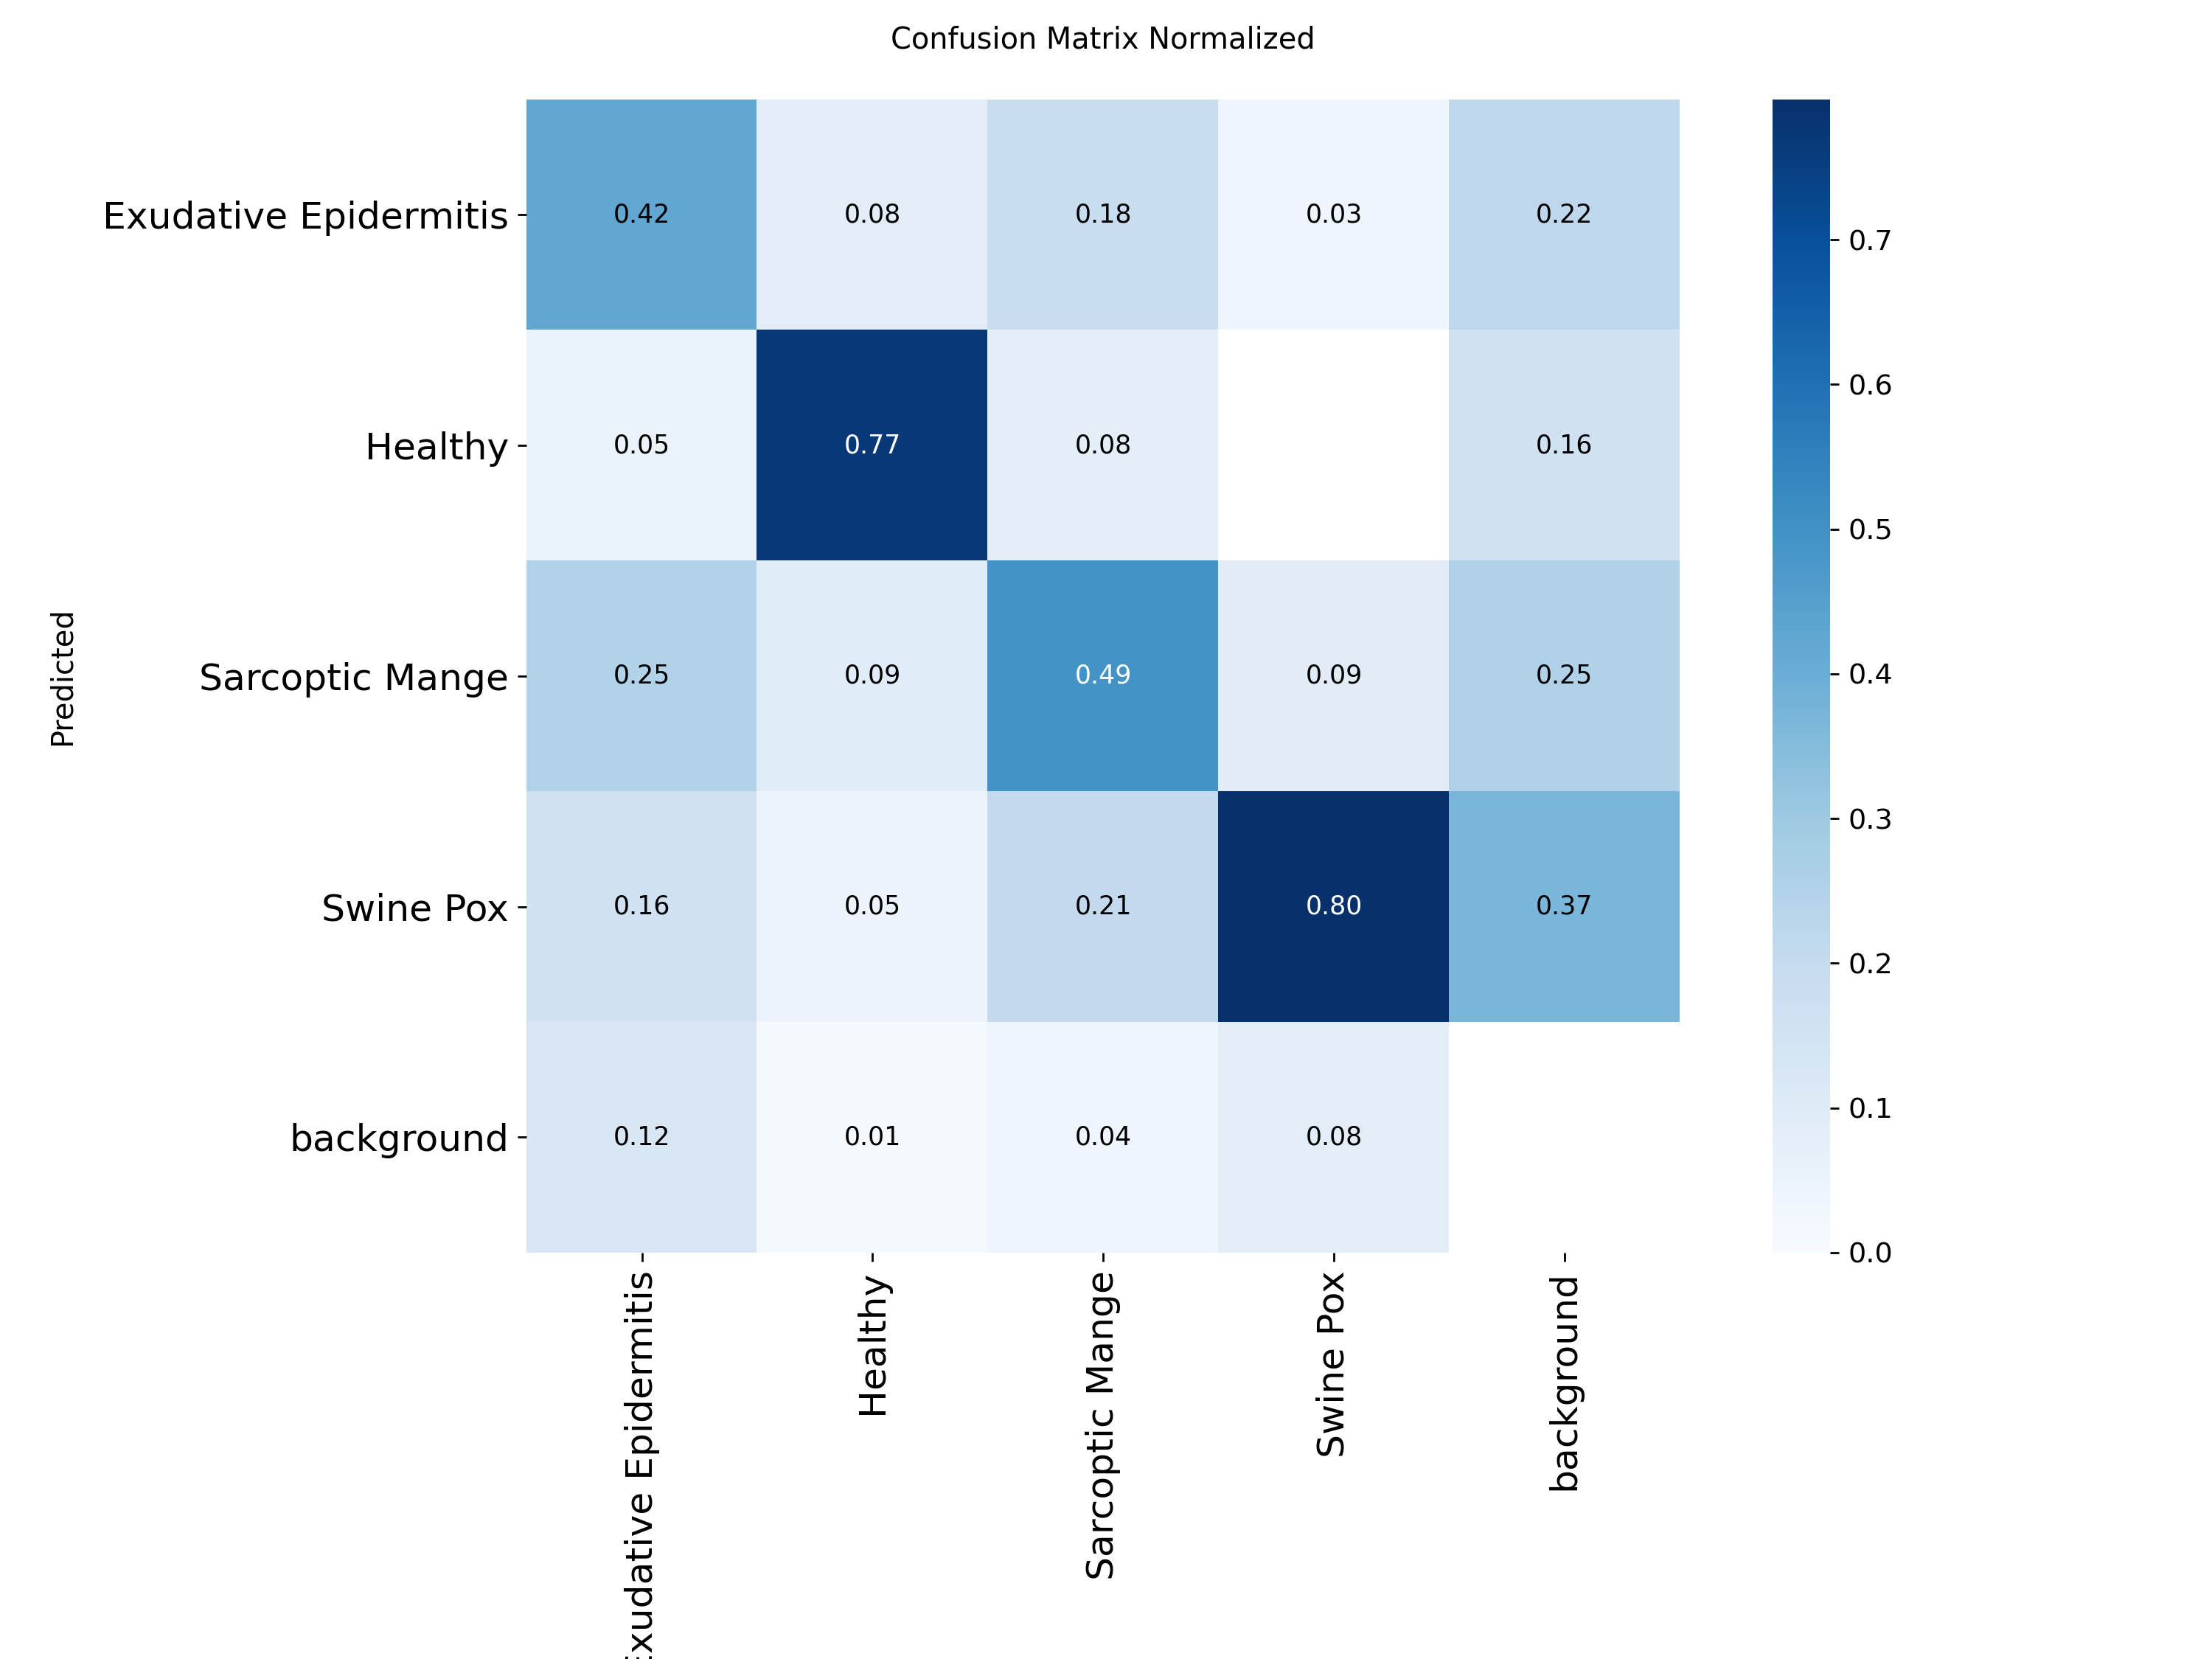

In [6]:
import numpy as np
from IPython.display import Image, display

best = YOLO(best_path)
eval_split = "test" if "test" in cfg else "val"
m = best.val(data=yaml_path, split=eval_split, plots=True, project="/content/runs", name="eval", exist_ok=True)

P, R = float(m.box.mp), float(m.box.mr)
F1 = 2 * P * R / (P + R + 1e-9)
print(f"\nSplit: {eval_split}")
print(f"Precision: {P:.4f}")
print(f"Recall:    {R:.4f}")
print(f"F1 score:  {F1:.4f}")
print(f"mAP50:     {m.box.map50:.4f}")
print(f"mAP50-95:  {m.box.map:.4f}")

print("\nPer-class F1:")
f1_arr = np.array(m.box.f1).flatten()
for idx, cls_i in enumerate(m.box.ap_class_index):
    print(f"  {best.names[int(cls_i)]}: F1 = {f1_arr[idx]:.4f}")

for fname in ["F1_curve.png", "PR_curve.png", "confusion_matrix_normalized.png"]:
    p = os.path.join(str(m.save_dir), fname)
    if os.path.exists(p):
        display(Image(p, width=700))

## 7. Subukan ang model sa test images (OpenCV)

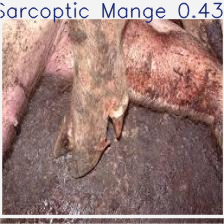

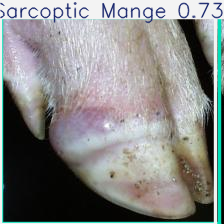

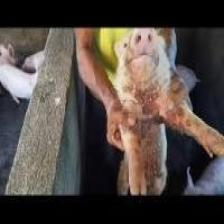

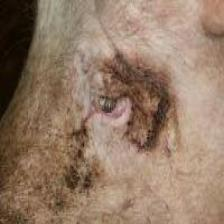

In [7]:
import cv2, random
from google.colab.patches import cv2_imshow

img_dir = os.path.join(DATA_DIR, "test" if "test" in cfg else "valid", "images")
all_imgs = os.listdir(img_dir)
for name in random.sample(all_imgs, min(4, len(all_imgs))):
    frame = cv2.imread(os.path.join(img_dir, name))
    res = best(frame, conf=0.35, verbose=False)
    cv2_imshow(res[0].plot())

## 8. Realtime script para sa PC mo (webcam, gamit ang best.pt)

In [8]:
script = '''import cv2
import sys
from ultralytics import YOLO

model = YOLO(sys.argv[1] if len(sys.argv) > 1 else "best.pt")
cap = cv2.VideoCapture(0)
if not cap.isOpened():
    raise SystemExit("Cannot open webcam")

while True:
    ok, frame = cap.read()
    if not ok:
        break
    results = model(frame, conf=0.4, verbose=False)
    cv2.imshow("Derma AI - Realtime (press q to quit)", results[0].plot())
    if cv2.waitKey(1) & 0xFF == ord("q"):
        break

cap.release()
cv2.destroyAllWindows()
'''
with open("/content/realtime_detect.py", "w") as f:
    f.write(script)
print("Saved. Sa PC: pip install ultralytics opencv-python  tapos  python realtime_detect.py best.pt")

Saved. Sa PC: pip install ultralytics opencv-python  tapos  python realtime_detect.py best.pt


## 9. Backup at download

In [9]:
import shutil
from google.colab import files

try:
    from google.colab import drive
    drive.mount("/content/drive")
    backup_dir = "/content/drive/MyDrive/derma_ai_model"
    os.makedirs(backup_dir, exist_ok=True)
    shutil.copy(best_path, backup_dir)
    print("Backed up to:", backup_dir)
except Exception as e:
    print("Drive backup skipped:", repr(e))

run_dir = os.path.dirname(os.path.dirname(best_path))
shutil.make_archive("/content/derma_results", "zip", run_dir)
files.download("/content/realtime_detect.py")
files.download("/content/derma_results.zip")

Drive backup skipped: ValueError('mount failed')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>